In [2]:
import argparse
import csv
from collections import deque
from dataclasses import dataclass
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

SLOT = 1 / 30
DEADLINE = 0.150
CAPACITY = 12
KEEP, FLUSH = 0, 1
SCENARIOS = ("Stable", "Fluctuating", "Sudden drop")
METRICS = ("Mean delay (ms)", "P95 delay (ms)", "Loss (%)", "On-time (%)")


@dataclass
class Frame:
    born: float
    bits: float
    important: bool


def make_trace(scenario, seed, length=300):
    rng = np.random.default_rng(seed)
    sizes = rng.integers(140_000, 240_001, length)
    important = np.arange(length) % 15 == 0
    if scenario == "Stable":
        rates = np.full(length, 8.0)
    elif scenario == "Fluctuating":
        rates = np.repeat(rng.choice([3, 6, 9], (length + 14) // 15), 15)[:length]
    else:
        rates = np.full(length, 9.0)
        rates[length // 3:2 * length // 3] = 2.0
    return sizes, important, rates * 1e6


class WirelessQueue:
    def __init__(self, trace):
        self.sizes, self.important, self.rates = trace
        self.queue = deque()
        self.index = 0
        self.delays = []
        self.dropped = 0
        self.enqueue()

    def enqueue(self):
        if len(self.queue) >= CAPACITY:
            return 1
        i = self.index
        self.queue.append(Frame(i * SLOT, float(self.sizes[i]), self.important[i]))
        return 0

    def state(self):
        if not self.queue:
            return None
        head = self.queue[0]
        count = len(self.queue)
        rate = self.rates[self.index]
        age = self.index * SLOT - head.born
        return (
            int(count >= 3) + int(count >= 7),
            int(rate >= 4e6) + int(rate >= 7e6),
            int(age >= 0.050) + int(age >= 0.100),
            int(head.important),
        )

    def gecko_action(self):
        if not self.queue:
            return KEEP
        backlog = sum(frame.bits for frame in self.queue)
        tail_age = self.index * SLOT - self.queue[-1].born
        return FLUSH if tail_age + backlog / self.rates[self.index] > DEADLINE else KEEP

    def flush(self, now, rate):
        kept = deque()
        bits_ahead = 0
        dropped = useful = 0
        for frame in self.queue:
            age = now - frame.born
            prediction = age + (bits_ahead + frame.bits) / rate
            if not frame.important and prediction > DEADLINE:
                dropped += 1
                useful += int(age < DEADLINE)
            else:
                kept.append(frame)
                bits_ahead += frame.bits
        self.queue = kept
        return dropped, useful

    def transmit(self, now, rate, duration):
        delivered = []
        budget = rate * duration
        while self.queue and budget > 0:
            head = self.queue[0]
            needed = head.bits
            if budget >= needed:
                budget -= needed
                finish = now + (duration - budget / rate)
                delivered.append(finish - head.born)
                self.queue.popleft()
            else:
                head.bits -= budget
                budget = 0
        return delivered

    def step(self, action):
        now = self.index * SLOT
        rate = self.rates[self.index]
        flushed = useful_drops = 0

        if action == FLUSH:
            flushed, useful_drops = self.flush(now, rate)

        delivered = self.transmit(now, rate, SLOT)
        self.delays.extend(delivered)
        self.index += 1
        done = self.index == len(self.sizes)
        overflow = 0

        if done:
            # Drain remaining packets
            drain_start = self.index * SLOT
            total_remaining = sum(f.bits for f in self.queue)
            drain_time = total_remaining / rate if rate > 0 else 0
            drain_delivered = self.transmit(drain_start, rate, drain_time + 1e-9)
            self.delays.extend(drain_delivered)
            resolved = len(delivered) + len(drain_delivered) + flushed
            on_time_count = sum(d <= DEADLINE for d in delivered) + sum(d <= DEADLINE for d in drain_delivered)
        else:
            overflow = self.enqueue()
            resolved = len(delivered) + flushed + overflow
            on_time_count = sum(d <= DEADLINE for d in delivered)

        self.dropped += flushed + overflow
        useful_drops += overflow

        delay_cost = sum(delay / DEADLINE for delay in delivered) / max(1, resolved)
        loss_cost = useful_drops / max(1, resolved)
        missed = flushed + overflow + sum(delay > DEADLINE for delay in delivered)
        miss_cost = missed / max(1, resolved)

        reward = -(0.5 * delay_cost + 0.5 * loss_cost + 2.0 * miss_cost)
        return (None if done else self.state()), reward

In [6]:
def train(episodes):
    rng = np.random.default_rng(7)
    # Four state axes followed by the action axis, for 54 states and 2 actions.
    q = np.zeros((3, 3, 3, 2, 2))
    history = []
    for episode in range(episodes):
        scenario = SCENARIOS[episode % len(SCENARIOS)]
        env = WirelessQueue(make_trace(scenario, episode))
        epsilon = max(0.05, 0.995 ** episode)
        state = env.state()
        total = 0.0
        while state is not None:
            if rng.random() < epsilon:
                action = int(rng.integers(2))
            else:
                action = int(np.argmax(q[state]))
            next_state, reward = env.step(action)
            entry = state + (action,)
            future = 0.0 if next_state is None else np.max(q[next_state])
            q[entry] += 0.10 * (reward + 0.95 * future - q[entry])
            total += reward
            state = next_state
        history.append(total / len(env.sizes))
    return q, history


def evaluate(policy, traces):
    delays = []
    generated = dropped = 0
    for trace in traces:
        env = WirelessQueue(trace)
        state = env.state()
        while state is not None:
            state, _ = env.step(policy(env))
        assert len(env.delays) + env.dropped == len(env.sizes)
        generated += len(env.sizes)
        dropped += env.dropped
        delays.extend(env.delays)

    # Delay is conditional on delivery. Loss and on-time use all arrivals.
    return (
        1000 * np.mean(delays) if delays else float("nan"),
        1000 * np.percentile(delays, 95) if delays else float("nan"),
        100 * dropped / generated,
        100 * sum(delay <= DEADLINE for delay in delays) / generated,
    )


def save_plots(history, results, policies, output):
    fig, ax = plt.subplots()
    episodes = np.arange(1, len(history) + 1)
    ax.plot(episodes, history, alpha=0.35, label="Episode")
    window = min(25, len(history))
    smoothed = np.convolve(history, np.ones(window) / window, mode="valid")
    ax.plot(episodes[window - 1:], smoothed, label=f"{window}-episode average")
    ax.set(xlabel="Episode", ylabel="Mean reward per decision", title="Training reward")
    ax.legend()
    fig.savefig(output / "training_reward.png", dpi=160, bbox_inches="tight")
    plt.close(fig)

    fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")
    positions = np.arange(len(SCENARIOS))
    for metric, ax in enumerate(axes.flat):
        for index, name in enumerate(policies):
            values = [results[scenario, name][metric] for scenario in SCENARIOS]
            ax.bar(positions + 0.25 * (index - 1), values, width=0.25, label=name)
        ax.set_xticks(positions, SCENARIOS)
        ax.set_title(METRICS[metric])
        if metric >= 2:
            ax.set_ylim(0, 105)
    axes[0, 0].legend()
    fig.savefig(output / "policy_comparison.png", dpi=160)
    plt.close(fig)


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--episodes", type=int, default=600)
    parser.add_argument("--output", type=Path, default=Path("queue_results"))
    # Use parser.parse_known_args() or pass args=[] to prevent parsing Jupyter runtime parameters
    args, unknown = parser.parse_known_args()
    if args.episodes < 1:
        parser.error("--episodes must be positive")

    q, history = train(args.episodes)
    policies = {
        "FIFO": lambda env: KEEP,
        "Gecko-inspired": lambda env: env.gecko_action(),
        "Q-learning": lambda env: int(np.argmax(q[env.state()]))
    }
    results = {}
    print(f"{'Scenario':14} {'Policy':16} {'Mean ms':>8} {'P95 ms':>8} {'Loss %':>8} {'On time %':>10}")
    for scenario in SCENARIOS:
        # Fixed, held-out traces shared by all policies.
        traces = [make_trace(scenario, seed) for seed in range(100_000, 100_020)]
        for name, policy in policies.items():
            scores = evaluate(policy, traces)
            results[scenario, name] = scores
            print(f"{scenario:14} {name:16} " + " ".join(f"{value:8.2f}" for value in scores))

    args.output.mkdir(parents=True, exist_ok=True)
    with (args.output / "metrics.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(("Scenario", "Policy", *METRICS))
        for (scenario, name), values in results.items():
            writer.writerow((scenario, name, *values))
    np.save(args.output / "q_table.npy", q)
    save_plots(history, results, policies, args.output)


if __name__ == "__main__":
    main()

Scenario       Policy            Mean ms   P95 ms   Loss %  On time %
Stable         FIFO                23.68    29.35     0.00   100.00
Stable         Gecko-inspired      23.68    29.35     0.00   100.00
Stable         Q-learning          23.68    29.35     0.00   100.00
Fluctuating    FIFO               182.66   525.38     4.68    50.27
Fluctuating    Gecko-inspired      52.96   138.77    12.50    87.25
Fluctuating    Q-learning          67.74   174.13    12.78    78.67
Sudden drop    FIFO               178.88  1091.51    17.98    64.38
Sudden drop    Gecko-inspired      38.74   141.29    20.70    77.92
Sudden drop    Q-learning          39.95   161.52    22.83    72.32


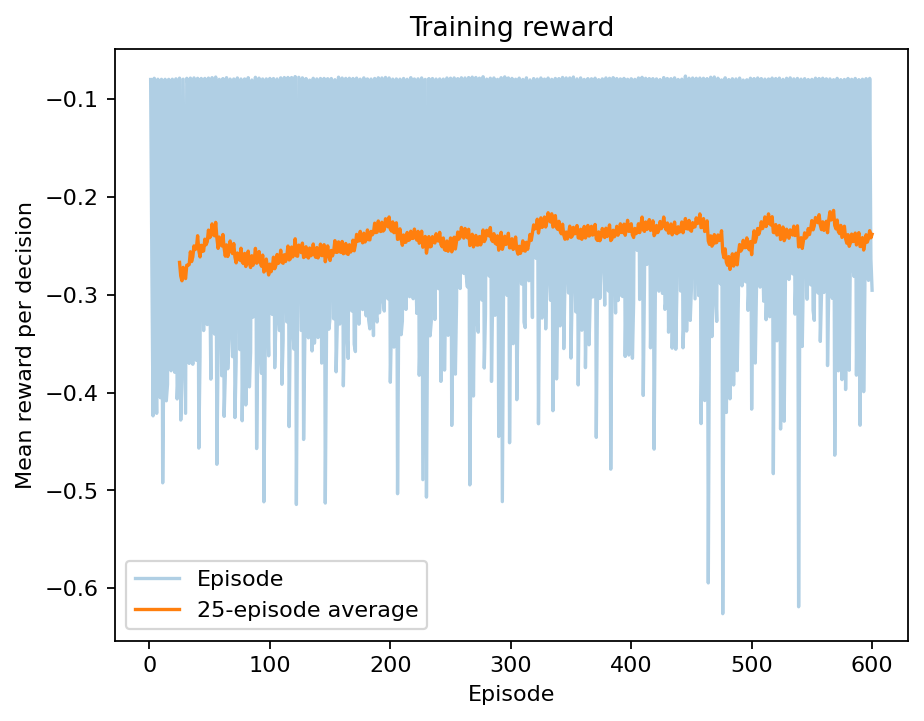

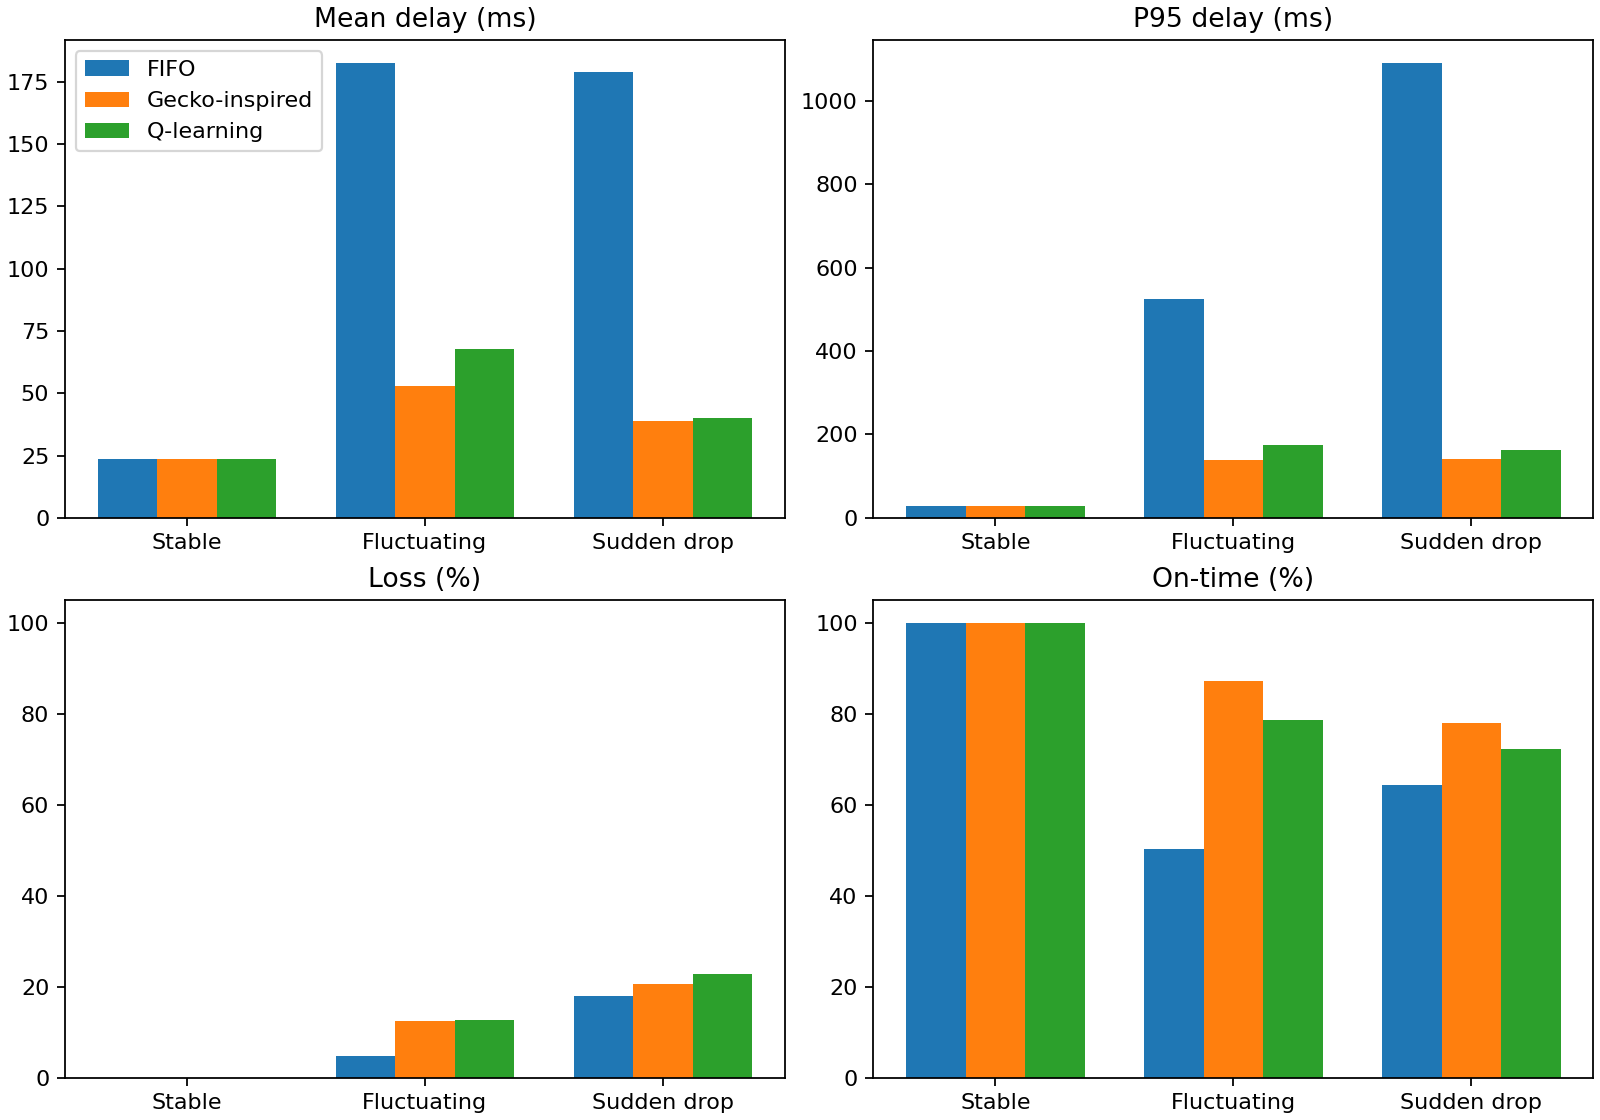

In [4]:
from IPython.display import Image, display

display(Image(filename="queue_results/training_reward.png"))
display(Image(filename="queue_results/policy_comparison.png"))

In [7]:
import shutil
from google.colab import files

shutil.make_archive("queue_results", "zip", "queue_results")
files.download("queue_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>